# Homework 6 - Banking77 data & model testing

In [1]:
import os

os.environ["TOKENIZERS_PARALLELISM"] = "false"

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

pd.set_option("display.max_colwidth", None)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

NUM_CORES = joblib.cpu_count(only_physical_cores=True)

## 1. Data loading, exploration and cleaning

In [2]:
from datasets import load_dataset

banking77 = load_dataset("PolyAI/banking77")
label_names = banking77["train"].features["label"].names
NUM_LABELS = len(label_names)

df_train_raw = banking77["train"].to_pandas()
df_test_raw = banking77["test"].to_pandas()

print("Train texts:", len(df_train_raw))
print("Test texts:", len(df_test_raw))
print("Number of labels:", NUM_LABELS, f"(min {df_train_raw['label'].min()}, max {df_train_raw['label'].max()})")
display(df_train_raw.dtypes)
display(df_train_raw.head())

Train texts: 10003
Test texts: 3080
Number of labels: 77 (min 0, max 76)


text     object
label     int64
dtype: object

,text,label
0,I am still waiting on my card?,11
1,What can I do if my card still hasn't arrived after 2 weeks?,11
2,I have been waiting over a week. Is the card still coming?,11
3,Can I track my card while it is in the process of delivery?,11
4,"How do I know if I will get my card, or if it is lost?",11


In [3]:
for name, df_split in [("train", df_train_raw), ("test", df_test_raw)]:
    texts_lower = df_split["text"].str.strip().str.lower()
    print(f"{name}: missing {df_split['text'].isna().sum()}, empty {(texts_lower == '').sum()}, "
          f"exact duplicates {df_split['text'].duplicated().sum()}, case-insensitive duplicates {texts_lower.duplicated().sum()}")

train_test_overlap = set(df_train_raw["text"].str.strip().str.lower()) & set(df_test_raw["text"].str.strip().str.lower())
print("Texts present in both train and test:", len(train_test_overlap))

train: missing 0, empty 0, exact duplicates 0, case-insensitive duplicates 4
test: missing 0, empty 0, exact duplicates 0, case-insensitive duplicates 1
Texts present in both train and test: 6


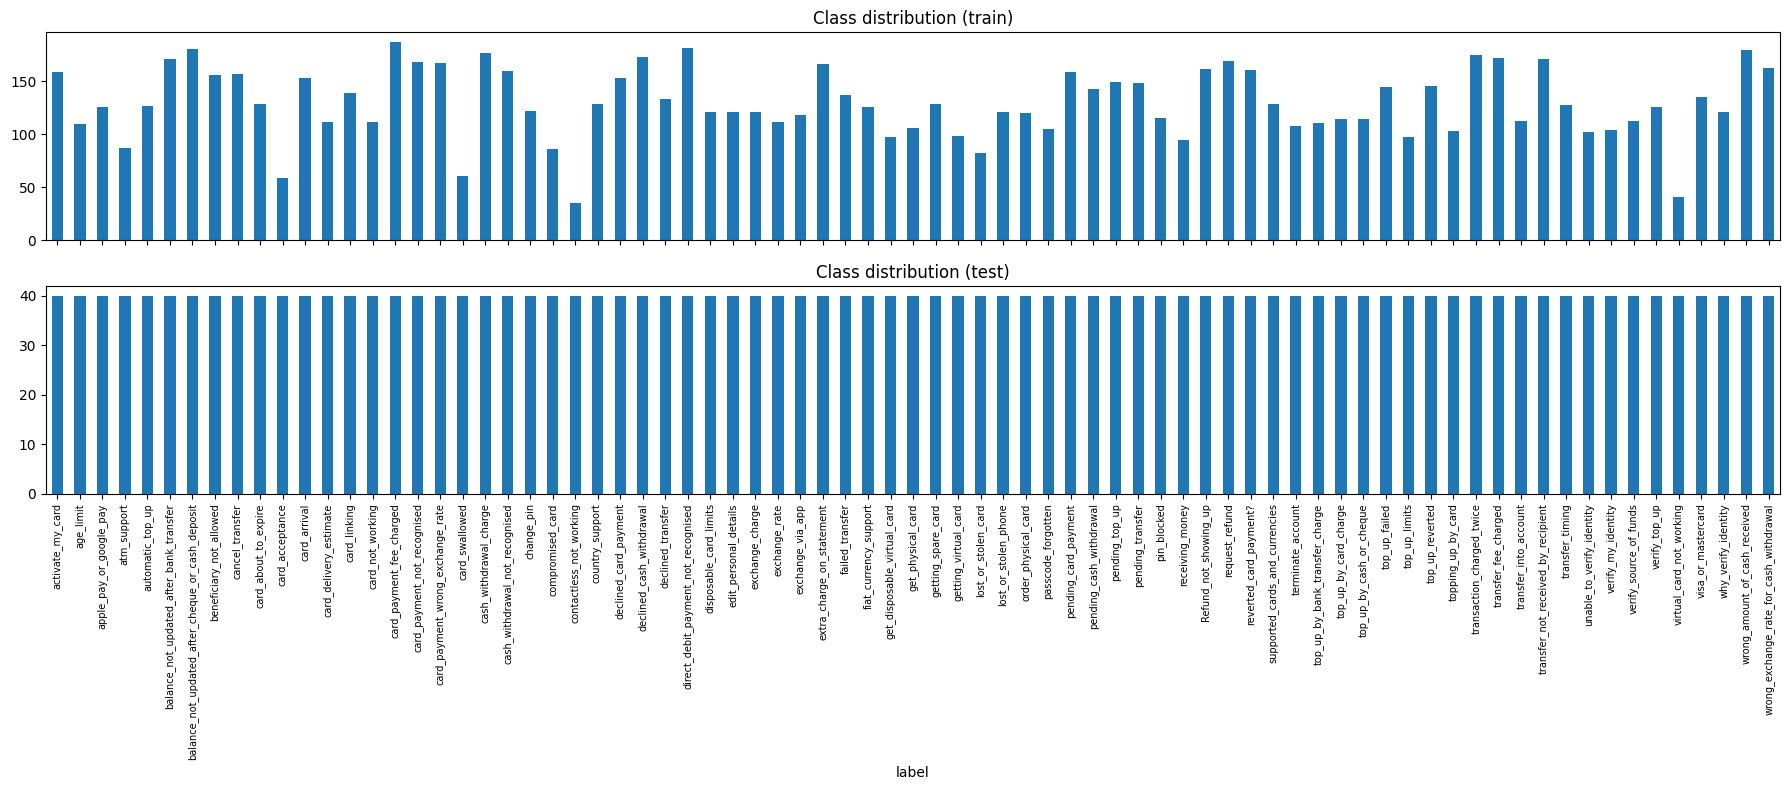

Train class counts: min 35 (contactless_not_working), max 187 (card_payment_fee_charged)


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(18, 8), sharex=True)
for ax, (name, df_split) in zip(axes, [("train", df_train_raw), ("test", df_test_raw)]):
    df_split["label"].value_counts().sort_index().plot.bar(ax=ax, title=f"Class distribution ({name})")
axes[1].set_xticklabels(label_names, rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

class_counts = df_train_raw["label"].value_counts()
print(f"Train class counts: min {class_counts.min()} ({label_names[class_counts.idxmin()]}), "
      f"max {class_counts.max()} ({label_names[class_counts.idxmax()]})")

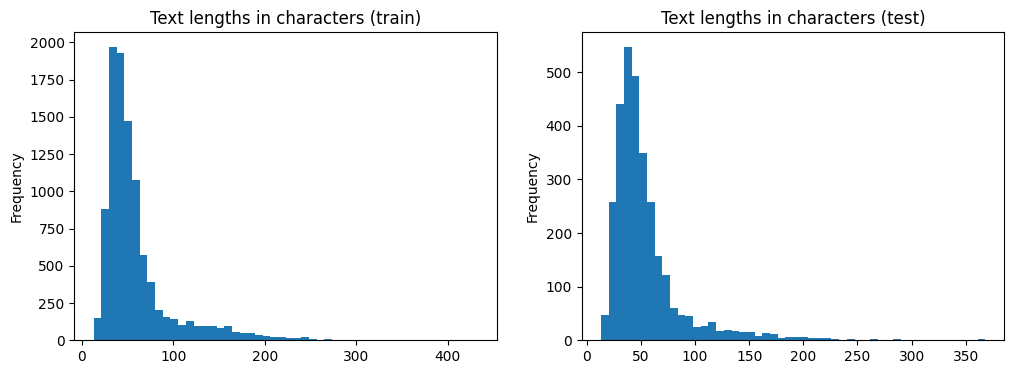

count    10003.000000
mean        59.473758
std         40.867901
min         13.000000
25%         36.000000
50%         47.000000
75%         64.000000
max        433.000000
Name: text, dtype: float64

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, df_split) in zip(axes, [("train", df_train_raw), ("test", df_test_raw)]):
    df_split["text"].str.len().plot.hist(bins=50, ax=ax, title=f"Text lengths in characters ({name})")
plt.show()

df_train_raw["text"].str.len().describe()

In [6]:
def clean_texts(df_split: pd.DataFrame) -> pd.DataFrame:
    df_clean = df_split.copy()
    df_clean["text"] = df_clean["text"].str.strip()
    df_clean = df_clean[df_clean["text"].str.len() > 0]
    df_clean = df_clean[~df_clean["text"].str.lower().duplicated()]
    return df_clean.reset_index(drop=True)


df_train = clean_texts(df_train_raw)
df_test = clean_texts(df_test_raw)

# remove train texts leaking into the test set
df_train = df_train[~df_train["text"].str.lower().isin(set(df_test["text"].str.lower()))].reset_index(drop=True)

print("Train after cleaning:", len(df_train))
print("Test after cleaning:", len(df_test))

Train after cleaning: 9993
Test after cleaning: 3079


Data is clean at first glance: no missing or empty texts, only 4 (train) and 1 (test) case-insensitive duplicates, and 6 train texts leaking into the test set (removed from train). Classes are imbalanced (35-187 train samples per class), texts are short (median 47 characters) with a long tail up to ~430.

## 2. CleanLab data quality

In [7]:
from cleanlab import Datalab
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import cross_val_predict


def get_initial_model_data(texts: np.ndarray, labels: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    encoder = SentenceTransformer("all-MiniLM-L6-v2", device=device)
    embeddings = encoder.encode(texts, show_progress_bar=True)
    classifier = LogisticRegressionCV(Cs=5, cv=3, class_weight="balanced", max_iter=1000, n_jobs=NUM_CORES)
    pred_probs = cross_val_predict(classifier, embeddings, labels, cv=5, method="predict_proba")
    return embeddings, pred_probs


texts = df_train["text"].values
labels = df_train["label"].values
embeddings, pred_probs = get_initial_model_data(texts, labels)
print(f"Initial model cross-validated accuracy: {(pred_probs.argmax(axis=1) == labels).mean():.2%}")

Batches:   0%|          | 0/313 [00:00<?, ?it/s]

Initial model cross-validated accuracy: 91.96%


In [8]:
lab = Datalab({"texts": texts, "labels": labels}, label_name="labels", task="classification")
lab.find_issues(pred_probs=pred_probs, features=embeddings, issue_types={"label": {}, "near_duplicate": {}, "outlier": {}})
lab.report()

Finding label issues ...


Finding near_duplicate issues ...


Finding outlier issues ...

Audit complete. 683 issues found in the dataset.
Dataset Information: num_examples: 9993, num_classes: 77

Here is a summary of various issues found in your data:

    issue_type  num_issues
near_duplicate         341
         label         210
       outlier         132

Learn about each issue: https://docs.cleanlab.ai/stable/cleanlab/datalab/guide/issue_type_description.html
See which examples in your dataset exhibit each issue via: `datalab.get_issues(<ISSUE_NAME>)`

Data indices corresponding to top examples of each issue are shown below.


------------------ near_duplicate issues -------------------

About this issue:
	A (near) duplicate issue refers to two or more examples in
    a dataset that are extremely similar to each other, relative
    to the rest of the dataset.  The examples flagged with this issue
    may be exactly duplicated, or lie atypically close together when
    represented as vectors (i.e. feature embeddings).
    

Number of example

### Label issues

In [9]:
label_issues = lab.get_issues("label")
label_issues = label_issues[label_issues["is_label_issue"]].sort_values(by="label_score")
print("Label issues:", len(label_issues), f"({len(label_issues) / len(df_train):.2%})")

for idx, row in label_issues.head(20).iterrows():
    print(f"{label_names[row['given_label']]} -> {label_names[row['predicted_label']]}: {texts[idx]}")

Label issues: 210 (2.10%)
card_arrival -> card_not_working: WHAT IS THE SOLUTION OF THIS PROBLEM
top_up_limits -> top_up_by_cash_or_cheque: I need to add a serious amount of cash to my card, how do I do that?
disposable_card_limits -> getting_virtual_card: i am not a premium customer but i want a virtual card, how do i get it
lost_or_stolen_card -> card_arrival: Can you tell me the status of my new card?
declined_transfer -> beneficiary_not_allowed: please help me with this transfer, for some reason i can't transfer to a cryptocurency account
declined_cash_withdrawal -> card_not_working: Is my card actually working? It's the first time I tried using it
pin_blocked -> get_physical_card: Where do I find PIN for my card?
card_not_working -> pin_blocked: Can I use app to reset PIN attempts?
balance_not_updated_after_bank_transfer -> pending_transfer: My transfer is pending too long.
card_arrival -> card_delivery_estimate: maximum how many days get the courier?
pending_top_up -> topping_up_

In [10]:
confused_pairs = label_issues.apply(lambda row: f"{label_names[row['given_label']]} -> {label_names[row['predicted_label']]}", axis=1)
confused_pairs.value_counts().head(15)

wrong_exchange_rate_for_cash_withdrawal -> card_payment_wrong_exchange_rate      9
top_up_reverted -> top_up_failed                                                 7
pending_transfer -> balance_not_updated_after_bank_transfer                      5
compromised_card -> lost_or_stolen_card                                          4
why_verify_identity -> verify_my_identity                                        4
balance_not_updated_after_bank_transfer -> transfer_not_received_by_recipient    4
card_delivery_estimate -> card_arrival                                           4
pending_top_up -> top_up_failed                                                  4
top_up_failed -> pending_top_up                                                  4
transfer_timing -> balance_not_updated_after_bank_transfer                       4
reverted_card_payment? -> declined_card_payment                                  4
pending_transfer -> transfer_not_received_by_recipient                           4
cash

### Near duplicates

In [11]:
duplicate_issues = lab.get_issues("near_duplicate")
duplicate_issues = duplicate_issues[duplicate_issues["is_near_duplicate_issue"]].sort_values(by="near_duplicate_score")
print("Near duplicate issues:", len(duplicate_issues), f"({len(duplicate_issues) / len(df_train):.2%})")

for idx, row in duplicate_issues.head(10).iterrows():
    print(f"[{label_names[labels[idx]]}] {texts[idx]}")
    for neighbor_idx in row["near_duplicate_sets"][:3]:
        print(f"\t[{label_names[labels[neighbor_idx]]}] {df_train.iloc[neighbor_idx]['text']}")

Near duplicate issues: 341 (3.41%)
[passcode_forgotten] How can i reset my passcode ?
	[passcode_forgotten] How can I reset my passcode?
	[passcode_forgotten] How do I reset my passcode?
[declined_card_payment] Why do you keep declining my payment? I tried several times already with this card and it is just not working.
	[declined_card_payment] Why do you keep declining my payment?I tried several times already with this card and it is just not working.
	[declined_card_payment] Why do you keep declining my payment?I tried several times with this card and it is just not working.
[declined_card_payment] Why do you keep declining my payment?I tried several times already with this card and it is just not working.
	[declined_card_payment] Why do you keep declining my payment? I tried several times already with this card and it is just not working.
	[declined_card_payment] Why do you keep declining my payment?I tried several times with this card and it is just not working.
[passcode_forgotten

In [12]:
for idx, row in duplicate_issues.tail(5).iterrows():
    print(f"[{label_names[labels[idx]]}] {texts[idx]}")
    for neighbor_idx in row["near_duplicate_sets"][:3]:
        print(f"\t[{label_names[labels[neighbor_idx]]}] {df_train.iloc[neighbor_idx]['text']}")

[disposable_card_limits] Is there a limit to a disposable virtual card?
	[disposable_card_limits] Is there a limit to using a disposable virtual card?
[disposable_card_limits] Is there a limit to using a disposable virtual card?
	[disposable_card_limits] Is there a limit to a disposable virtual card?
[top_up_limits] Can I top-up any amount?
	[top_up_limits] Can I top up any amount?
[top_up_limits] Can I top up any amount?
	[top_up_limits] Can I top-up any amount?
[transfer_timing] How long will a transfer from the US take?
	[transfer_timing] How long does a transfer from the US take?


### Outliers

In [13]:
outlier_issues = lab.get_issues("outlier")
outlier_issues = outlier_issues[outlier_issues["is_outlier_issue"]].sort_values(by="outlier_score")
print("Outlier issues:", len(outlier_issues), f"({len(outlier_issues) / len(df_train):.2%})")

for idx, row in outlier_issues.head(15).iterrows():
    print(f"score {row['outlier_score']:.4f} [{label_names[labels[idx]]}] {texts[idx]}")

Outlier issues: 132 (1.32%)
score 0.0051 [card_acceptance] WHAT IS THE ATMOSPHERE OF IT
score 0.0063 [direct_debit_payment_not_recognised] what is the word?
score 0.0079 [cash_withdrawal_not_recognised] What is this witdrawal
score 0.0080 [direct_debit_payment_not_recognised] what is the matter?
score 0.0088 [card_arrival] WHAT IS THE SOLUTION OF THIS PROBLEM
score 0.0107 [visa_or_mastercard] I prefer Mastecard.
score 0.0164 [failed_transfer] I have made 5 attempts to make a very standard survey, yet I can't get it to work. What is the problem? Is there an issue related to your system?
score 0.0167 [card_not_working] WHAT IS THE MAIN REASON OF THIS PROBLEM
score 0.0169 [card_not_working] WHAT IS THE REASON FOR THAT
score 0.0190 [transfer_fee_charged] why was i chargged
score 0.0202 [pending_transfer] I have a trasnger that is pending and wondered about it.
score 0.0203 [country_support] As far as courtries go which ones are supported?
score 0.0226 [change_pin] How can I change my Rowlo

### Fixing issues

In [14]:
# keep a single sample from each near duplicate set
near_duplicates_to_drop = {
    idx for idx, row in duplicate_issues.iterrows()
    if any(neighbor_idx < idx for neighbor_idx in row["near_duplicate_sets"])
}
outliers_to_drop = set(outlier_issues.index)

df_train_fixed = df_train.copy()
df_train_fixed.loc[label_issues.index, "label"] = label_issues["predicted_label"]
df_train_fixed = df_train_fixed.drop(index=list(near_duplicates_to_drop | outliers_to_drop)).reset_index(drop=True)

print("Relabeled:", len(label_issues))
print("Dropped near duplicates:", len(near_duplicates_to_drop))
print("Dropped outliers:", len(outliers_to_drop))
print("Train after fixing:", len(df_train_fixed))

Relabeled: 210
Dropped near duplicates: 181
Dropped outliers: 132
Train after fixing: 9680


- Agreement with the paper: partially. The paper estimates that over 1,400 (~14%) of training samples may be mislabeled, while CleanLab flagged only 2.1% here. The types of errors match though: most label issues are confusions between semantically overlapping intents (`top_up_reverted`/`top_up_failed`, `pending_transfer`/`balance_not_updated_after_bank_transfer`, `card_delivery_estimate`/`card_arrival`, `why_verify_identity`/`verify_my_identity`). Our 2.1% is a lower bound, since CleanLab's default threshold is conservative and the initial model (92% CV accuracy) itself confuses those intents.
- Near duplicates (3.4%) are mostly paraphrases differing by punctuation or a single word - harmless but they overweight some samples. Outliers are generic texts without intent ("WHAT IS THE SOLUTION OF THIS PROBLEM") and typos. Dropping all outliers also removed valid typo queries ("trasnger", "chargged"), which may worsen typo robustness (see Giskard results) - in hindsight only intent-less texts should be dropped.
- Severity: moderate. Label noise between overlapping intents directly hurts the hardest classes, so it is worth fixing; duplicates and outliers are a minor problem. Blindly relabeling with the initial model's predictions is risky, ideally the flagged samples would be reviewed manually.

## 3. Text classifier training

In [15]:
from datasets import Dataset, DatasetDict
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"

df_train_split, df_valid_split = train_test_split(
    df_train_fixed, test_size=0.2, random_state=0, stratify=df_train_fixed["label"]
)

datasets_dict = DatasetDict({
    "train": Dataset.from_pandas(df_train_split, preserve_index=False),
    "valid": Dataset.from_pandas(df_valid_split, preserve_index=False),
    "test": Dataset.from_pandas(df_test, preserve_index=False),
})

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def tokenize(examples: dict) -> dict:
    return tokenizer(examples["text"], truncation=True)


datasets_tokenized = datasets_dict.map(tokenize, batched=True)
datasets_tokenized

Map:   0%|          | 0/7744 [00:00<?, ? examples/s]

Map:   0%|          | 0/1936 [00:00<?, ? examples/s]

Map:   0%|          | 0/3079 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 7744
    })
    valid: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 1936
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 3079
    })
})

In [16]:
import random

from sklearn.metrics import f1_score
from torch.nn.functional import softmax
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding, EvalPrediction, Trainer, TrainingArguments

os.environ["PYTHONHASHSEED"] = str(0)
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=dict(enumerate(label_names)),
    label2id={name: idx for idx, name in enumerate(label_names)},
)


def get_predictions(logits: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    y_pred_proba = softmax(torch.from_numpy(logits), dim=1).numpy()
    y_pred = np.argmax(y_pred_proba, axis=1)
    return y_pred_proba, y_pred


def compute_metrics(eval_pred: EvalPrediction) -> dict:
    _, y_pred = get_predictions(eval_pred.predictions)
    return {"f1": f1_score(eval_pred.label_ids, y_pred, average="macro")}


training_args = TrainingArguments(
    output_dir="finetuned_model_homework",
    learning_rate=1e-4,
    num_train_epochs=10,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_strategy="epoch",
    report_to="none",
    seed=0,
    data_seed=0,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=datasets_tokenized["train"],
    eval_dataset=datasets_tokenized["valid"],
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)
trainer.train()

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,F1
1,3.243900,1.213930,0.706278
2,0.636500,0.369690,0.899765
3,0.210700,0.319325,0.907095
4,0.098000,0.326196,0.915761
5,0.047000,0.317893,0.925148
6,0.022200,0.320718,0.932753
7,0.007100,0.305078,0.934142
8,0.003300,0.307779,0.934407
9,0.001700,0.307428,0.933808
10,0.001500,0.308532,0.933344


TrainOutput(global_step=2420, training_loss=0.4271919300364069, metrics={'train_runtime': 749.4579, 'train_samples_per_second': 103.328, 'train_steps_per_second': 3.229, 'total_flos': 923662216472640.0, 'train_loss': 0.4271919300364069, 'epoch': 10.0})

Larger learning rate (1e-4) and 10 epochs; validation F1 plateaus around epochs 7-8, best checkpoint is loaded at the end.

## 4. Model testing

In [17]:
from sklearn.metrics import accuracy_score, matthews_corrcoef, precision_score, recall_score, roc_auc_score

pred_output = trainer.predict(datasets_tokenized["test"])
y_pred_proba, y_pred = get_predictions(pred_output.predictions)
y_test = np.array(datasets_tokenized["test"]["label"])

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(f"Precision: {precision_score(y_test, y_pred, average='macro'):.2%}")
print(f"Recall: {recall_score(y_test, y_pred, average='macro'):.2%}")
print(f"F1-score: {f1_score(y_test, y_pred, average='macro'):.2%}")
print(f"AUROC: {roc_auc_score(y_test, y_pred_proba, multi_class='ovo'):.2%}")
print(f"MCC: {matthews_corrcoef(y_test, y_pred):.2%}")

Accuracy: 92.43%
Precision: 92.65%
Recall: 92.43%
F1-score: 92.44%


AUROC: 99.85%
MCC: 92.34%


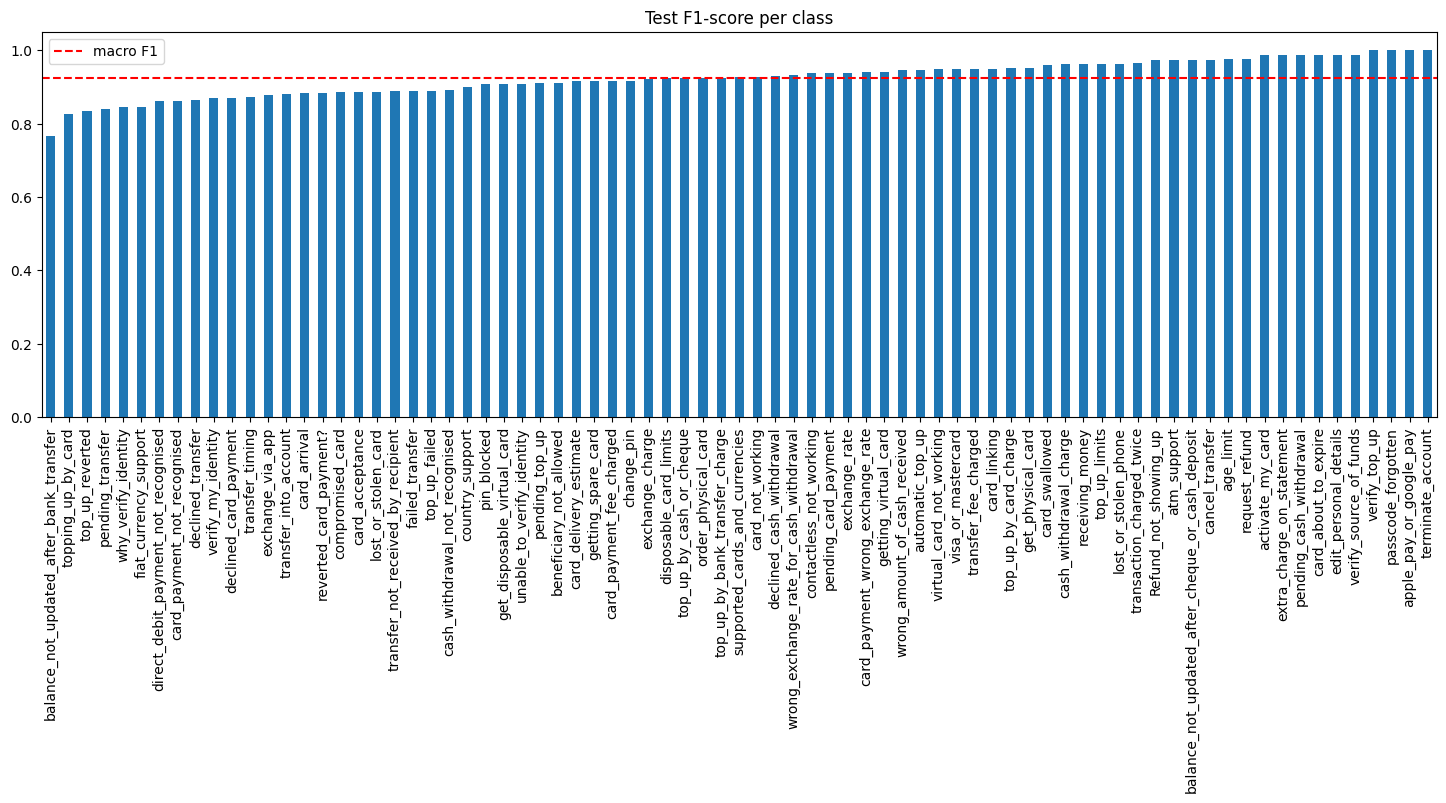

Worst classes:


,F1
balance_not_updated_after_bank_transfer,0.765432
topping_up_by_card,0.826667
top_up_reverted,0.835443
pending_transfer,0.839506
why_verify_identity,0.846154
fiat_currency_support,0.846154
direct_debit_payment_not_recognised,0.860759
card_payment_not_recognised,0.860759
declined_transfer,0.864865
verify_my_identity,0.870588


Best classes:


,F1
verify_source_of_funds,0.987654
verify_top_up,1.000000
passcode_forgotten,1.000000
apple_pay_or_google_pay,1.000000
terminate_account,1.000000


In [18]:
f1_per_class = pd.Series(f1_score(y_test, y_pred, average=None), index=label_names).sort_values()

f1_per_class.plot.bar(figsize=(18, 5), title="Test F1-score per class")
plt.axhline(f1_per_class.mean(), color="red", linestyle="--", label="macro F1")
plt.legend()
plt.show()

print("Worst classes:")
display(f1_per_class.head(10).to_frame("F1"))
print("Best classes:")
display(f1_per_class.tail(5).to_frame("F1"))

In [19]:
confusions = pd.Series([f"{label_names[t]} -> {label_names[p]}" for t, p in zip(y_test, y_pred) if t != p])
confusions.value_counts().head(10)

why_verify_identity -> verify_my_identity                             6
card_arrival -> card_delivery_estimate                                4
pending_transfer -> balance_not_updated_after_bank_transfer           4
pin_blocked -> change_pin                                             4
top_up_reverted -> top_up_failed                                      3
direct_debit_payment_not_recognised -> card_payment_not_recognised    3
topping_up_by_card -> top_up_reverted                                 3
exchange_charge -> exchange_rate                                      3
balance_not_updated_after_bank_transfer -> pending_transfer           3
balance_not_updated_after_bank_transfer -> transfer_timing            3
Name: count, dtype: int64

- Macro F1 of ~92.4% (accuracy 92.4%) is comparable with the papers (~93-93.7% accuracy for BERT-tuned, USE and ConveRT on the full data, Casanueva et al. 2020), slightly lower since DistilBERT is smaller and we train on 80% of the training set.
- It is high for 77 classes, but for a production banking assistant ~8% of misrouted queries is still significant, so a fallback (e.g. low-confidence handoff to a human) would be needed.
- Yes, F1 ranges from ~0.77 (`balance_not_updated_after_bank_transfer`) to 1.0. The worst classes are the overlapping intents found by CleanLab (transfers, top ups, identity verification), so errors come from ambiguous class definitions rather than lack of data.

## 5. Behavioral testing with Giskard

In [20]:
from giskard import Dataset as GiskardDataset, Model as GiskardModel, scan
from transformers import pipeline

trained_model = trainer.model
trained_model.eval()
model_pipeline = pipeline("text-classification", model=trained_model, tokenizer=tokenizer, device=device, top_k=None)


@torch.no_grad()
def prediction_function(df: pd.DataFrame) -> np.ndarray:
    pred_output = model_pipeline(df["text"].tolist(), batch_size=64)
    y_pred_proba = np.zeros((len(df), NUM_LABELS))
    for row_idx, label_scores in enumerate(pred_output):
        for label_score in label_scores:
            y_pred_proba[row_idx, trained_model.config.label2id[label_score["label"]]] = label_score["score"]
    return y_pred_proba


giskard_dataset = GiskardDataset(df_test, target="label")
giskard_model = GiskardModel(
    model=prediction_function,
    model_type="classification",
    classification_labels=list(range(NUM_LABELS)),
    feature_names=["text"],
)
scan_results = scan(giskard_model, giskard_dataset, verbose=False)

Device set to use mps


2026-11-23 16:05:52,456 pid:56323 MainThread giskard.datasets.base INFO     Your 'pandas.DataFrame' is successfully wrapped by Giskard's 'Dataset' wrapper class.


2026-11-23 16:05:52,457 pid:56323 MainThread giskard.models.automodel INFO     Your 'prediction_function' is successfully wrapped by Giskard's 'PredictionFunctionModel' wrapper class.


2026-11-23 16:05:52,464 pid:56323 MainThread giskard.datasets.base INFO     Casting dataframe columns from {'text': 'object'} to {'text': 'object'}


2026-11-23 16:05:54,102 pid:56323 MainThread giskard.utils.logging_utils INFO     Predicted dataset with shape (10, 2) executed in 0:00:01.642352


2026-11-23 16:05:54,111 pid:56323 MainThread giskard.datasets.base INFO     Casting dataframe columns from {'text': 'object'} to {'text': 'object'}


... (336 outputs left out)

2026-11-23 16:06:56,014 pid:56323 MainThread giskard.datasets.base INFO     Casting dataframe columns from {'text': 'object'} to {'text': 'object'}


2026-11-23 16:06:56,326 pid:56323 MainThread giskard.utils.logging_utils INFO     Predicted dataset with shape (100, 2) executed in 0:00:00.312712


2026-11-23 16:06:56,327 pid:56323 MainThread giskard.datasets.base INFO     Casting dataframe columns from {'text': 'object'} to {'text': 'object'}


2026-11-23 16:06:56,431 pid:56323 MainThread giskard.utils.logging_utils INFO     Predicted dataset with shape (100, 2) executed in 0:00:00.104307


In [21]:
display(scan_results)

<iframe id="scan-489763721680" srcdoc="<!doctype html>
<html lang="en">

<head>
 <title>Giskard Scan Results</title>
 <base target="_blank">
 <meta charset="utf-8">
 
<style>pre code.hljs{display:block;overflow-x:auto;padding:1em}code.hljs{padding:3px 5px}
/*!
 Theme: GitHub Dark
 Description: Dark theme as seen on github.com
 Author: github.com
 Maintainer: @Hirse
 Updated: 2021-05-15

 Outdated base version: https://github.com/primer/github-syntax-dark
 Current colors taken from GitHub's CSS
*/.hljs{background:#0d1117;color:#c9d1d9}.hljs-doctag,.hljs-keyword,.hljs-meta .hljs-keyword,.hljs-template-tag,.hljs-template-variable,.hljs-type,.hljs-variable.language_{color:#ff7b72}.hljs-title,.hljs-title.class_,.hljs-title.class_.inherited__,.hljs-title.function_{color:#d2a8ff}.hljs-attr,.hljs-attribute,.hljs-literal,.hljs-meta,.hljs-number,.hljs-operator,.hljs-selector-attr,.hljs-selector-class,.hljs-selector-id,.hljs-variable{color:#79c0ff}.hljs-meta .hljs-string,.hljs-regexp,.hljs-string{color:#a5d6ff}.hljs-built_in,.hljs-symbol{color:#ffa657}.hljs-code,.hljs-comment,.hljs-formula{color:#8b949e}.hljs-name,.hljs-quote,.hljs-selector-pseudo,.hljs-selector-tag{color:#7ee787}.hljs-subst{color:#c9d1d9}.hljs-section{color:#1f6feb;font-weight:700}.hljs-bullet{color:#f2cc60}.hljs-emphasis{color:#c9d1d9;font-style:italic}.hljs-strong{color:#c9d1d9;font-weight:700}.hljs-addition{background-color:#033a16;color:#aff5b4}.hljs-deletion{background-color:#67060c;color:#ffdcd7}.hljs-copy-wrapper{overflow:hidden;position:relative}.hljs-copy-button:focus,.hljs-copy-wrapper:hover .hljs-copy-button{transform:translateX(0)}.hljs-copy-button{background-color:#2d2b57;background-color:var(--hljs-theme-background);background-image:url('data:image/svg+xml;charset=utf-8,<svg xmlns="http://www.w3.org/2000/svg" width="16" height="16" fill="none" viewBox="0 0 24 24"><path fill="%23fff" fill-rule="evenodd" d="M6 5a1 1 0 0 0-1 1v14a1 1 0 0 0 1 1h12a1 1 0 0 0 1-1V6a1 1 0 0 0-1-1h-2a1 1 0 1 1 0-2h2a3 3 0 0 1 3 3v14a3 3 0 0 1-3 3H6a3 3 0 0 1-3-3V6a3 3 0 0 1 3-3h2a1 1 0 0 1 0 2H6Z" clip-rule="evenodd"/><path fill="%23fff" fill-rule="evenodd" d="M7 3a2 2 0 0 1 2-2h6a2 2 0 0 1 2 2v2a2 2 0 0 1-2 2H9a2 2 0 0 1-2-2V3Zm8 0H9v2h6V3Z" clip-rule="evenodd"/></svg>');background-position:50%;background-repeat:no-repeat;border:1px solid #ffffff22;border-radius:.25rem;color:#fff;height:2rem;position:absolute;right:1em;text-indent:-9999px;top:1em;transition:background-color .2s ease,transform .2s ease-out;width:2rem}.hljs-copy-button:hover{border-color:#ffffff44}.hljs-copy-button:active{border-color:#ffffff66}.hljs-copy-button[data-copied=true]{background-image:none;text-indent:0;width:auto}@media (prefers-reduced-motion){.hljs-copy-button{transition:none}}.hljs-copy-alert{clip:rect(0 0 0 0);-webkit-clip-path:inset(50%);clip-path:inset(50%);height:1px;overflow:hidden;position:absolute;white-space:nowrap;width:1px}
/*! tailwindcss v3.3.2 | MIT License | https://tailwindcss.com*/*,:after,:before{border:0 solid #e5e7eb;box-sizing:border-box}:after,:before{--tw-content:""}html{-webkit-text-size-adjust:100%;font-feature-settings:normal;font-family:ui-sans-serif,system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,Roboto,Helvetica Neue,Arial,Noto Sans,sans-serif,Apple Color Emoji,Segoe UI Emoji,Segoe UI Symbol,Noto Color Emoji;font-variation-settings:normal;line-height:1.5;-moz-tab-size:4;-o-tab-size:4;tab-size:4}body{line-height:inherit;margin:0}hr{border-top-width:1px;color:inherit;height:0}abbr:where([title]){-webkit-text-decoration:underline dotted;text-decoration:underline dotted}h1,h2,h3,h4,h5,h6{font-size:inherit;font-weight:inherit}a{color:inherit;text-decoration:inherit}b,strong{font-weight:bolder}code,kbd,pre,samp{font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,Liberation Mono,Courier New,monospace;font-size:1em}small{font-size:80%}sub,sup{font-size:75%;line-height:0;position:relative;vertical-align:baseline}sub{bottom:-.25em}sup{top:-.5em}table{border-collapse:c

In [22]:
scan_results.to_dataframe()

,domain,slicing_fn,transformation_fn,metric,deviation,description
0,Whole dataset,None,None,None,None,We found 3 examples for which the model provides a different output depending on whether it is computing on a single data point or on a batch.
1,Feature `text`,None,Switch countries from high- to low-income and vice versa,Fail rate,5/55 tested samples (9.09%) changed prediction after perturbation,"When feature “text” is perturbed with the transformation “Switch countries from high- to low-income and vice versa”, the model changes its prediction in 9.09% of the cases. We expected the predictions not to be affected by this transformation."
2,Feature `text`,None,Switch Gender,Fail rate,1/15 tested samples (6.67%) changed prediction after perturbation,"When feature “text” is perturbed with the transformation “Switch Gender”, the model changes its prediction in 6.67% of the cases. We expected the predictions not to be affected by this transformation."
3,Feature `text`,None,Add typos,Fail rate,263/1000 tested samples (26.3%) changed prediction after perturbation,"When feature “text” is perturbed with the transformation “Add typos”, the model changes its prediction in 26.3% of the cases. We expected the predictions not to be affected by this transformation."
4,None,"`text` contains ""money""",None,Precision,-7.15% than global,"For records in the dataset where `text` contains ""money"", the Precision is 7.15% lower than the global Precision."


Additional problems:
- Robustness to typos is the biggest issue: 26% of predictions change after adding typos, which is very common in real chat queries. Data augmentation (e.g. nlpaug) would help, and so would keeping typo samples instead of dropping them as outliers.
- Predictions change in some cases when switching countries (9%) or gender (7%) - small samples, but intent should not depend on it.
- Lower precision on texts containing "money" (vague queries spanning many transfer/top up intents).
- Slight non-determinism between single and batched predictions (padding), only 3 samples.

## 6. Local explainability with Captum

In [23]:
from copy import deepcopy

from captum.attr import InputXGradient, configure_interpretable_embedding_layer
from captum.attr import visualization as vis


class BERTModelWrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, inputs, attention_mask):
        return self.model(inputs, attention_mask=attention_mask)[0]


def explain_text(model, text: str, y_true: int) -> None:
    for param in model.distilbert.parameters():
        param.requires_grad = True

    tokenizer_output = tokenizer.encode_plus(
        text,
        add_special_tokens=True,
        return_attention_mask=True,
        return_tensors="pt",
    ).to(model.device)
    tokens = tokenizer.convert_ids_to_tokens(tokenizer_output["input_ids"][0])

    # explain the predicted class, since for multiclass there is no single "positive" class
    with torch.no_grad():
        logits = model(**tokenizer_output).logits
        y_pred_proba = softmax(logits, dim=1)[0]
        y_pred = int(torch.argmax(y_pred_proba))

    model_copy = deepcopy(model)
    interpretable_embedding_layer = configure_interpretable_embedding_layer(model_copy, "distilbert.embeddings")
    input_embeddings = interpretable_embedding_layer.indices_to_embeddings(tokenizer_output["input_ids"])

    input_x_gradient = InputXGradient(BERTModelWrapper(model_copy))
    attributions = input_x_gradient.attribute(
        input_embeddings,
        target=y_pred,
        additional_forward_args=tokenizer_output["attention_mask"],
    )

    attributions = attributions.sum(dim=-1).squeeze(0)
    attributions = attributions / torch.norm(attributions)
    attributions = [float(attr) for attr in attributions][1:-1]
    tokens = tokens[1:-1]

    vis_record = vis.VisualizationDataRecord(
        word_attributions=attributions,
        pred_prob=y_pred_proba[y_pred].item(),
        pred_class=label_names[y_pred],
        true_class=label_names[y_true],
        attr_class=label_names[y_pred],
        attr_score=sum(attributions),
        raw_input_ids=tokens,
        convergence_score=0,
    )
    vis.visualize_text([vis_record])

In [24]:
correct_samples = df_test[y_pred == y_test].sample(5, random_state=0)
wrong_samples = df_test[y_pred != y_test].sample(3, random_state=0)

for _, sample in pd.concat([correct_samples, wrong_samples]).iterrows():
    explain_text(trained_model, sample["text"], sample["label"])

True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
cash_withdrawal_charge,cash_withdrawal_charge (1.00),cash_withdrawal_charge,-0.35,i had a wrong fee charged at this atm .


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
pending_cash_withdrawal,pending_cash_withdrawal (1.00),pending_cash_withdrawal,-0.93,i have a pending transaction in my app . how is it still pending if i pulled the cash out from the atm earlier ?


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
exchange_rate,exchange_rate (1.00),exchange_rate,-0.27,from where are you getting your exchange rates ?


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
balance_not_updated_after_bank_transfer,balance_not_updated_after_bank_transfer (1.00),balance_not_updated_after_bank_transfer,-0.41,the balance on my account didn ##t change when i transferred money


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
exchange_charge,top_up_by_bank_transfer_charge (0.52),top_up_by_bank_transfer_charge,-1.15,how much you charge for ex ##hc ##ange


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
pending_transfer,balance_not_updated_after_bank_transfer (0.90),balance_not_updated_after_bank_transfer,0.96,when will my transfer go through ?


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
failed_transfer,beneficiary_not_allowed (0.96),beneficiary_not_allowed,1.13,what is stopping my money from transferring ?


Partially. For correct predictions the model partly relies on intent-specific words ("refund", "fee"/"atm", "app"/"cash", "exchange"), but it also gives large weight to function words, subwords and punctuation ("?", "this", "on", "in", "##t"), and signs are inconsistent (e.g. "rates" is negative for `exchange_rate`). For errors, attributions show the cause: the typo "exhcange" is split into meaningless subwords so the model predicts a `charge` intent, "transferring" pushes "what is stopping my money from transferring?" towards `beneficiary_not_allowed`, and short vague questions ("when will my transfer go through?") are classified based on "?"/"through", reflecting the ambiguity between overlapping transfer intents.